# Lab 1 – Introduction to Deep Learning (AI & Cybersecurity)
## Task 3 – When a Feature Biases the Model

Goal: test whether the locked-in Task 2C baseline genuinely learns intrusion-traffic dynamics or relies on a spurious `Destination Port == 80` shortcut, then remove `Destination Port`, re-run the preprocessing pipeline, analyze the resulting `PortScan` collapse, and argue the de-duplication decision for the port-free dataset used in Tasks 4–5.

**Budget note:** Task 3 performs inference only (no retraining) and data re-preprocessing, so **0 training runs** are spent from our ~25-run budget (cumulative usage remains **5 / 25** runs, with **20** remaining for Tasks 4–5).

Notebook outline:
1. Setup & loading Task 1 data and Task 2C locked-in baseline model
2. Port-80 bias inspection & domain analysis (`Brute Force` always on port 80: dataset artefact vs. general property)
3. Counterfactual experiment (predict-then-check): changing `Brute Force` destination port `80 → 8080` in the test set only (inference, no retraining) + port-sensitivity curve
4. Removing `Destination Port` & redoing preprocessing (`clean, split, scale`): before-vs-after class counts and the `PortScan` collapse (`4,849 → 285`, `-94.12%`)
5. Mechanism of the `PortScan` collapse & what the Task 2 model actually "knew" about `PortScan`
6. The de-duplication dilemma: quantitative leakage analysis (`dedup=True` vs. `dedup=False`), argued decision, and export of the port-free dataset (`task3_outputs/task3_preprocessed_no_port.npz`)
7. Consolidated answers to all Task 3 questions

## 1. Setup, Data & Task 2C Baseline Loading

We fix random seeds (`SEED = 42`), set single-thread CPU execution for determinism, and load:
- raw `dataset_lab_1.csv` (for port inspection and port-free re-preprocessing),
- Task 1 preprocessed arrays & scaler parameters from `task1_outputs/task1_preprocessed_with_port.npz` (with an inline Task 1 fallback if absent), and
- the frozen Task 2C `1×64 ReLU` baseline checkpoint from `task2_outputs/task2c_baseline_relu.pt` (with an inline fallback that retrains `Run 1` deterministically if absent).

In [1]:
import os, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

OUT_DIR = "task3_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
CSV_PATH = "dataset_lab_1.csv"
T1_NPZ = "task1_outputs/task1_preprocessed_with_port.npz"
T2_CKPT = "task2_outputs/task2c_baseline_relu.pt"

assert os.path.exists(CSV_PATH), f"Dataset not found: {CSV_PATH}"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

LABEL = "Label"
df_raw = pd.read_csv(CSV_PATH)


def preprocess_pipeline(df_in, drop_port=False, seed=SEED, dedup=True, test_size=0.15, val_size=0.15):
    d = df_in.copy()
    if drop_port and "Destination Port" in d.columns:
        d = d.drop(columns="Destination Port")
    feats = [c for c in d.columns if c != LABEL]
    log_raw = d[LABEL].value_counts()

    d[feats] = d[feats].replace([np.inf, -np.inf], np.nan)
    d = d.dropna()
    log_nan = d[LABEL].value_counts()

    d = d[~(d[feats] < 0).any(axis=1)]
    log_neg = d[LABEL].value_counts()

    if dedup:
        d = d.drop_duplicates()
    d = d.reset_index(drop=True)
    log_dedup = d[LABEL].value_counts()

    clean_tbl = pd.DataFrame({
        "0_raw": log_raw,
        "1_after_NaN_inf": log_nan,
        "2_after_negative": log_neg,
        "3_after_dedup": log_dedup,
    }).fillna(0).astype(int)
    clean_tbl.loc["TOTAL"] = clean_tbl.sum()

    classes = sorted(d[LABEL].unique())
    cls2id = {c: i for i, c in enumerate(classes)}
    y = d[LABEL].map(cls2id).values
    i_tr, i_tmp = train_test_split(np.arange(len(d)), test_size=val_size + test_size, random_state=seed, stratify=y)
    i_va, i_te = train_test_split(i_tmp, test_size=test_size / (val_size + test_size), random_state=seed, stratify=y[i_tmp])

    binary_or_small = {"Fwd PSH Flags", "SYN Flag Count", "Down/Up Ratio"}
    categorical_like = {"Destination Port"}
    log_feats = [c for c in feats if c not in (binary_or_small | categorical_like)]

    def make_raw(ix):
        return d.loc[ix, feats].to_numpy(dtype="float32")

    def tf(ix):
        x = d.loc[ix, feats].copy()
        x[log_feats] = np.log1p(x[log_feats])
        return x

    X_tr_tf, X_va_tf, X_te_tf = tf(i_tr), tf(i_va), tf(i_te)
    scaler = StandardScaler().fit(X_tr_tf)
    return {
        "X_train": scaler.transform(X_tr_tf).astype("float32"), "y_train": y[i_tr],
        "X_val": scaler.transform(X_va_tf).astype("float32"), "y_val": y[i_va],
        "X_test": scaler.transform(X_te_tf).astype("float32"), "y_test": y[i_te],
        "X_train_raw": make_raw(i_tr),
        "X_val_raw": make_raw(i_va),
        "X_test_raw": make_raw(i_te),
        "scaler_mean": scaler.mean_, "scaler_scale": scaler.scale_,
        "features": feats, "log_features": log_feats, "classes": classes,
        "clean_table": clean_tbl, "df_clean": d,
        "indices": {"train": i_tr, "val": i_va, "test": i_te},
    }


class FFNN(nn.Module):
    def __init__(self, in_dim=16, hidden=64, out_dim=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out_dim),
        )

    def forward(self, x):
        return self.net(x)


def load_t1_and_t2():
    if os.path.exists(T1_NPZ):
        d = np.load(T1_NPZ, allow_pickle=False)
        t1 = {k: d[k] for k in d.files}
        t1["features"] = t1["features"].tolist()
        t1["log_features"] = t1["log_features"].tolist()
        t1["classes"] = t1["classes"].tolist()
    else:
        t1 = preprocess_pipeline(df_raw, drop_port=False, dedup=True)

    features = t1["features"]
    classes = t1["classes"]
    model = FFNN(len(features), 64, len(classes))
    if os.path.exists(T2_CKPT):
        ckpt = torch.load(T2_CKPT, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])
    else:
        np.random.seed(SEED)
        torch.manual_seed(SEED)
        gen = torch.Generator().manual_seed(SEED)
        X_tr_t, y_tr_t = torch.from_numpy(t1["X_train"]), torch.from_numpy(t1["y_train"]).long()
        X_va_t, y_va_t = torch.from_numpy(t1["X_val"]), torch.from_numpy(t1["y_val"]).long()
        opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.0)
        crit = nn.CrossEntropyLoss()
        best_loss, best_state, wait = float("inf"), None, 0
        for _ in range(100):
            model.train()
            perm = torch.randperm(len(X_tr_t), generator=gen)
            Xs, ys = X_tr_t[perm], y_tr_t[perm]
            for i in range(0, len(Xs), 64):
                opt.zero_grad(set_to_none=True)
                loss = crit(model(Xs[i : i + 64]), ys[i : i + 64])
                loss.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                vl = crit(model(X_va_t), y_va_t).item()
            if vl < best_loss - 1e-4:
                best_loss = vl
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
                wait = 0
            else:
                wait += 1
                if wait >= 12:
                    break
        model.load_state_dict(best_state)
    model.eval()
    return t1, model


t1_data, baseline_model = load_t1_and_t2()
FEATURES = t1_data["features"]
LOG_FEATURES = set(t1_data["log_features"])
CLASSES = t1_data["classes"]
X_te = t1_data["X_test"]
X_te_raw = t1_data["X_test_raw"]
y_te = t1_data["y_test"]

with torch.no_grad():
    orig_preds = baseline_model(torch.from_numpy(X_te)).argmax(dim=1).numpy()

print(f"Task 1 features ({len(FEATURES)}): {FEATURES}")
print(f"Classes: {CLASSES}")
print(
    f"Verified Task 2C baseline on Test ({len(y_te)} flows): "
    f"Accuracy = {accuracy_score(y_te, orig_preds):.4f}, "
    f"Macro-F1 = {f1_score(y_te, orig_preds, average='macro'):.4f}"
)

Task 1 features (16): ['Flow Duration', 'Flow IAT Mean', 'Fwd PSH Flags', 'Bwd Packet Length Mean', 'Bwd Packet Length Max', 'Flow Bytes/s', 'Down/Up Ratio', 'SYN Flag Count', 'Fwd Packet Length Mean', 'Fwd IAT Std', 'Packet Length Mean', 'Fwd Packet Length Max', 'Subflow Fwd Packets', 'Flow Packets/s', 'Total Fwd Packets', 'Destination Port']
Classes: ['Benign', 'Brute Force', 'DoS Hulk', 'PortScan']
Verified Task 2C baseline on Test (4408 flows): Accuracy = 0.9853, Macro-F1 = 0.9742


## 2. Port-80 Bias Inspection & Domain Analysis

Before running the counterfactual test, we inspect how `Destination Port` is distributed across the 4 classes in the raw dataset.

**Q: Is "Brute Force always on port 80" a property of brute-force attacks in general, or an artefact of this dataset? If your model sees this, what is it likely to learn?**
- **Dataset artefact, not a general property of brute-force attacks.** In real network environments, brute-force credential attacks target many services and ports depending on the exposed service: SSH (`22`, `2222`), FTP (`21`), RDP (`3389`), SMB (`445`), Telnet (`23`), HTTPS (`443`, `8443`), or reverse-proxied/alternate HTTP (`8080`, `8000`). In this CICIDS2017 subset, `Brute Force` (and `DoS Hulk`) were captured exclusively against an HTTP web server listening on port `80` (`1,507 / 1,507 = 100%` of `Brute Force` flows use `Destination Port == 80`).
- **What the model is likely to learn:** Because `Destination Port` is fed as a continuous standardized feature (`port 80 → z = -0.4427`), a feed-forward network can achieve near-zero loss on the training set by learning a **spurious shortcut (Clever Hans effect)**: gating `Brute Force` predictions on `Destination Port ≈ 80` (low/negative standardized port coordinate) rather than learning port-invariant brute-force flow behavior.

In [2]:
port_summary = df_raw.groupby(LABEL)["Destination Port"].agg(
    n_flows="count",
    n_distinct_ports="nunique",
    top_port=lambda s: int(s.value_counts().index[0]),
    top_port_count=lambda s: int(s.value_counts().iloc[0]),
    top_port_pct=lambda s: round(s.value_counts().iloc[0] / len(s) * 100, 2),
    port80_pct=lambda s: round((s == 80).mean() * 100, 2),
)
display(port_summary)

port_idx = FEATURES.index("Destination Port")
scaler_mean = t1_data["scaler_mean"]
scaler_scale = t1_data["scaler_scale"]
z_80 = (80.0 - scaler_mean[port_idx]) / scaler_scale[port_idx]
z_8080 = (8080.0 - scaler_mean[port_idx]) / scaler_scale[port_idx]
print(f"Destination Port scaler params (train): mean={scaler_mean[port_idx]:.2f}, std={scaler_scale[port_idx]:.2f}")
print(f"Standardized z-score: port 80 -> {z_80:+.4f}  |  port 8080 -> {z_8080:+.4f}  (shift = {z_8080 - z_80:+.4f} std)")

,n_flows,n_distinct_ports,top_port,top_port_count,top_port_pct,port80_pct
Label,,,,,,
Benign,20000,3603,53,8530,42.65,10.80
Brute Force,1507,1,80,1507,100.00,100.00
DoS Hulk,5000,1,80,5000,100.00,100.00
PortScan,5000,995,5631,13,0.26,0.16


Destination Port scaler params (train): mean=7880.35, std=17620.11
Standardized z-score: port 80 -> -0.4427  |  port 8080 -> +0.0113  (shift = +0.4540 std)


## 3. Counterfactual Experiment: Changing Brute Force `Destination Port` `80 → 8080` (Test Set Only)

### Predict first (before running counterfactual inference)
In the held-out test set, all `214` `Brute Force` flows arrive on `Destination Port == 80` (`z = -0.4427`). We construct a counterfactual test set `X_te_cf` where **only** the `Destination Port` of the `214` `Brute Force` test flows is changed from `80` to `8080` (`z = +0.0113`), leaving all other `15` flow features and all non-`Brute Force` test flows completely unchanged, and run inference with the frozen Task 2C baseline (no retraining).

**Hypothesis:** Because the model used `Destination Port ≈ 80` (`z < 0`) as a shortcut for `Brute Force`—and because shifting `80 → 8080` flips `z` from negative (`-0.4427`) to positive (`+0.0113`) while keeping packet/timing features typical of short web requests—we predict that **`Brute Force` recall will collapse sharply from `1.0000` toward `0`**, with most shifted `Brute Force` attacks falling back to `Benign`.

,Original Test (BF port=80),Counterfactual Test (BF port=8080),Delta (CF - Orig)
Accuracy,0.9853,0.9394,-0.0458
Macro-F1,0.9742,0.7539,-0.2202
BF Precision,0.8917,0.3158,-0.5759
BF Recall,1.0000,0.0561,-0.9439
BF F1,0.9427,0.0952,-0.8475
DoS Hulk F1,0.9683,0.9683,0.0000
PortScan F1,0.9966,0.9966,0.0000
Benign F1,0.9891,0.9557,-0.0334


=== Counterfactual Test Classification Report (BF Port 80 -> 8080, NO retraining) ===
              precision    recall  f1-score   support

      Benign     0.9243    0.9893    0.9557      2887
 Brute Force     0.3158    0.0561    0.0952       214
    DoS Hulk     0.9892    0.9483    0.9683       580
    PortScan     0.9986    0.9945    0.9966       727

    accuracy                         0.9394      4408
   macro avg     0.8070    0.7470    0.7539      4408
weighted avg     0.9155    0.9394    0.9223      4408



,Pred: Benign,Pred: Brute Force,Pred: DoS Hulk,Pred: PortScan
True: Benign,2856,25,5,1
True: Brute Force,202,12,0,0
True: DoS Hulk,29,1,550,0
True: PortScan,3,0,1,723


Prediction breakdown for the 214 counterfactual Brute Force flows: {'Benign': 202, 'Brute Force': 12}


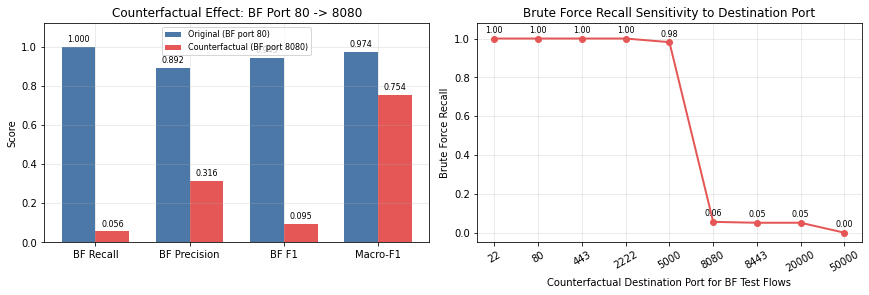

In [3]:
bf_id = CLASSES.index("Brute Force")
bf_mask = (y_te == bf_id)
assert np.all(X_te_raw[bf_mask, port_idx] == 80.0), "Expected all test Brute Force flows on port 80"

def transform_raw_matrix(X_raw_mat):
    df_tmp = pd.DataFrame(X_raw_mat, columns=FEATURES)
    for col in FEATURES:
        if col in LOG_FEATURES:
            df_tmp[col] = np.log1p(df_tmp[col])
    return ((df_tmp.to_numpy(dtype="float64") - scaler_mean) / scaler_scale).astype("float32")

X_te_cf_raw = X_te_raw.copy()
X_te_cf_raw[bf_mask, port_idx] = 8080.0
X_te_cf = transform_raw_matrix(X_te_cf_raw)

# Verify only Brute Force rows changed
assert np.abs(X_te[~bf_mask] - X_te_cf[~bf_mask]).max() < 1e-6

with torch.no_grad():
    cf_preds = baseline_model(torch.from_numpy(X_te_cf)).argmax(dim=1).numpy()

def metrics_summary(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=range(len(CLASSES)), zero_division=0)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(y_true, y_pred, average="macro"),
        "BF Precision": p[bf_id],
        "BF Recall": r[bf_id],
        "BF F1": f1[bf_id],
        "DoS Hulk F1": f1[CLASSES.index("DoS Hulk")],
        "PortScan F1": f1[CLASSES.index("PortScan")],
        "Benign F1": f1[CLASSES.index("Benign")],
    }

cf_cmp = pd.DataFrame({
    "Original Test (BF port=80)": metrics_summary(y_te, orig_preds),
    "Counterfactual Test (BF port=8080)": metrics_summary(y_te, cf_preds),
})
cf_cmp["Delta (CF - Orig)"] = cf_cmp["Counterfactual Test (BF port=8080)"] - cf_cmp["Original Test (BF port=80)"]
display(cf_cmp.round(4))

print("=== Counterfactual Test Classification Report (BF Port 80 -> 8080, NO retraining) ===")
print(classification_report(y_te, cf_preds, target_names=CLASSES, digits=4, zero_division=0))

cm_cf = pd.DataFrame(
    confusion_matrix(y_te, cf_preds),
    index=[f"True: {c}" for c in CLASSES],
    columns=[f"Pred: {c}" for c in CLASSES],
)
display(cm_cf)
bf_pred_dist = pd.Series(cf_preds[bf_mask]).map(lambda i: CLASSES[i]).value_counts().to_dict()
print(f"Prediction breakdown for the {bf_mask.sum()} counterfactual Brute Force flows: {bf_pred_dist}")

# Port sensitivity sweep on Brute Force test flows
sweep_ports = [22, 80, 443, 2222, 5000, 8080, 8443, 20000, 50000]
sweep_rows = []
for p in sweep_ports:
    X_sw = X_te.copy()
    z_p = (float(p) - scaler_mean[port_idx]) / scaler_scale[port_idx]
    X_sw[bf_mask, port_idx] = z_p
    with torch.no_grad():
        pr = baseline_model(torch.from_numpy(X_sw)).argmax(dim=1).numpy()
    sweep_rows.append({"Port": p, "z_port": round(z_p, 4), "BF_Recall": float((pr[bf_mask] == bf_id).mean())})
sweep_df = pd.DataFrame(sweep_rows)

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.2))
bar_metrics = ["BF Recall", "BF Precision", "BF F1", "Macro-F1"]
x_pos = np.arange(len(bar_metrics))
w = 0.36
orig_vals = [cf_cmp.loc[m, "Original Test (BF port=80)"] for m in bar_metrics]
cf_vals = [cf_cmp.loc[m, "Counterfactual Test (BF port=8080)"] for m in bar_metrics]
b1 = axes[0].bar(x_pos - w / 2, orig_vals, width=w, label="Original (BF port 80)", color="#4c78a8")
b2 = axes[0].bar(x_pos + w / 2, cf_vals, width=w, label="Counterfactual (BF port 8080)", color="#e45756")
for bars in (b1, b2):
    for b in bars:
        axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.015, f"{b.get_height():.3f}", ha="center", va="bottom", fontsize=8)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(bar_metrics)
axes[0].set_ylim(0, 1.12)
axes[0].set_ylabel("Score")
axes[0].set_title("Counterfactual Effect: BF Port 80 -> 8080")
axes[0].legend(fontsize=8)

axes[1].plot(np.arange(len(sweep_df)), sweep_df["BF_Recall"], marker="o", lw=2.0, color="#e45756")
axes[1].set_xticks(np.arange(len(sweep_df)))
axes[1].set_xticklabels([str(p) for p in sweep_df["Port"]], rotation=30)
axes[1].set_ylim(-0.05, 1.08)
axes[1].set_xlabel("Counterfactual Destination Port for BF Test Flows")
axes[1].set_ylabel("Brute Force Recall")
axes[1].set_title("Brute Force Recall Sensitivity to Destination Port")
for xi, r_val in enumerate(sweep_df["BF_Recall"]):
    axes[1].text(xi, r_val + 0.03, f"{r_val:.2f}", ha="center", fontsize=8)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_task3_counterfactual_port8080.png")
plt.show()

### Reconcile & Counterfactual Question

- **Q: Did your prediction hold? Explain what this reveals about what the model was really using to detect Brute Force.**
  **Yes, completely.** Shifting only `Destination Port` from `80` to `8080` on the `214` test `Brute Force` flows—with zero retraining and all other 15 traffic features untouched—causes **`Brute Force` recall to collapse by `94.39` percentage points (`1.0000 → 0.0561`, dropping from `214/214` detected attacks down to `12/214`)**. `202` out of `214` (`94.39%`) shifted `Brute Force` attacks are misclassified as **`Benign`**, `Brute Force` F1 crashes from `0.9427` to `0.0952`, and overall `Macro-F1` drops from `0.9742` to `0.7539` (while accuracy only drops from `0.9853` to `0.9394` because `Brute Force` is `4.85%` of the test set).
  - **What this reveals:** The port sensitivity curve shows `1.0000` recall for ports `22`, `80`, `443`, and `2222` (all sharing `z < -0.32`), then a sharp cliff to `0.0561` at port `8080` (`z = +0.0113`) and `0.0000` at port `50000`. Because `Destination Port` was passed as a standardized continuous scalar, the Task 2C network did **not** learn a port-invariant behavioural signature of brute-force login attempts; it learned a **low-port gate (`z < 0`)** paired with short HTTP-like flow features, defaulting to `Benign` whenever a brute-force attack runs on a non-standard port such as `8080`.

## 4. Removing `Destination Port` & Redoing Preprocessing

We now drop `Destination Port` from the original `dataset_lab_1.csv` (leaving `15` behavioral flow features) and re-run the exact Task 1 cleaning pipeline (`inf → NaN`, drop `NaN`, drop negative rows, drop exact duplicates).

Cleaning steps WITHOUT Destination Port:


,0_raw,1_after_NaN_inf,2_after_negative,3_after_dedup
Label,,,,
Benign,20000,19992,19990,16888
Brute Force,1507,1507,1507,1427
DoS Hulk,5000,4982,4982,3868
PortScan,5000,4999,4999,285
TOTAL,31507,31480,31478,22468


,Raw,Valid (pre-dedup),Clean WITH port,Clean WITHOUT port,Lost vs WITH port,Lost vs WITH port (%),Share WITH port (%),Share WITHOUT port (%)
Label,,,,,,,,
Benign,20000,19990,19240,16888,2352,12.22,65.48,75.16
Brute Force,1507,1507,1427,1427,0,0.00,4.86,6.35
DoS Hulk,5000,4982,3868,3868,0,0.00,13.16,17.22
PortScan,5000,4999,4849,285,4564,94.12,16.50,1.27
TOTAL,31507,31478,29384,22468,6916,23.54,100.00,100.00


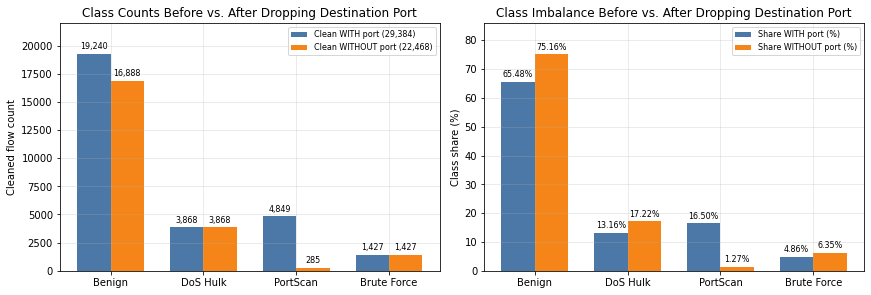

Valid PortScan flows (pre-dedup): 4,999  ->  Unique 15-feature templates: 285
Top-10 templates account for 1,449 / 4,999 (29.0%) PortScan flows.


,occurrences,Flow Duration,Flow IAT Mean,Total Fwd Packets,Fwd Packet Length Max,Bwd Packet Length Max,Flow Bytes/s,Flow Packets/s
0,215,43,43.0,1,2,6,186046.52,46511.630
1,207,43,43.0,1,0,6,139534.89,46511.630
2,196,44,44.0,1,0,6,136363.64,45454.547
3,189,44,44.0,1,2,6,181818.19,45454.547
4,139,49,49.0,1,0,6,122448.98,40816.330


In [4]:
t1_with_port = preprocess_pipeline(df_raw, drop_port=False, dedup=True)
t3_no_port = preprocess_pipeline(df_raw, drop_port=True, dedup=True)

tbl_wp = t1_with_port["clean_table"]
tbl_np = t3_no_port["clean_table"]

print("Cleaning steps WITHOUT Destination Port:")
display(tbl_np)

cmp_clean = pd.DataFrame({
    "Raw": tbl_wp["0_raw"],
    "Valid (pre-dedup)": tbl_wp["2_after_negative"],
    "Clean WITH port": tbl_wp["3_after_dedup"],
    "Clean WITHOUT port": tbl_np["3_after_dedup"],
})
cmp_clean["Lost vs WITH port"] = cmp_clean["Clean WITH port"] - cmp_clean["Clean WITHOUT port"]
cmp_clean["Lost vs WITH port (%)"] = (cmp_clean["Lost vs WITH port"] / cmp_clean["Clean WITH port"] * 100).round(2)
cmp_clean["Share WITH port (%)"] = (cmp_clean["Clean WITH port"].drop("TOTAL") / cmp_clean.loc["TOTAL", "Clean WITH port"] * 100).round(2)
cmp_clean["Share WITHOUT port (%)"] = (cmp_clean["Clean WITHOUT port"].drop("TOTAL") / cmp_clean.loc["TOTAL", "Clean WITHOUT port"] * 100).round(2)
cmp_clean.loc["TOTAL", "Share WITH port (%)"] = 100.0
cmp_clean.loc["TOTAL", "Share WITHOUT port (%)"] = 100.0
display(cmp_clean)
cmp_clean.to_csv(f"{OUT_DIR}/cleaning_comparison_port_vs_noport.csv")

# Plot before vs after port removal
cls_order = ["Benign", "DoS Hulk", "PortScan", "Brute Force"]
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.2))
x = np.arange(len(cls_order))
w = 0.36
c_wp = [cmp_clean.loc[c, "Clean WITH port"] for c in cls_order]
c_np = [cmp_clean.loc[c, "Clean WITHOUT port"] for c in cls_order]
b1 = axes[0].bar(x - w / 2, c_wp, width=w, label="Clean WITH port (29,384)", color="#4c78a8")
b2 = axes[0].bar(x + w / 2, c_np, width=w, label="Clean WITHOUT port (22,468)", color="#f58518")
for bars in (b1, b2):
    for b in bars:
        axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 250, f"{int(b.get_height()):,}", ha="center", va="bottom", fontsize=8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(cls_order)
axes[0].set_ylim(0, 22000)
axes[0].set_ylabel("Cleaned flow count")
axes[0].set_title("Class Counts Before vs. After Dropping Destination Port")
axes[0].legend(fontsize=8)

s_wp = [cmp_clean.loc[c, "Share WITH port (%)"] for c in cls_order]
s_np = [cmp_clean.loc[c, "Share WITHOUT port (%)"] for c in cls_order]
b3 = axes[1].bar(x - w / 2, s_wp, width=w, label="Share WITH port (%)", color="#4c78a8")
b4 = axes[1].bar(x + w / 2, s_np, width=w, label="Share WITHOUT port (%)", color="#f58518")
for bars in (b3, b4):
    for b in bars:
        axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 1.0, f"{b.get_height():.2f}%", ha="center", va="bottom", fontsize=8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(cls_order)
axes[1].set_ylim(0, 86)
axes[1].set_ylabel("Class share (%)")
axes[1].set_title("Class Imbalance Before vs. After Dropping Destination Port")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_task3_class_collapse_port_removed.png")
plt.show()

# Inspect why PortScan collapses: check repeated 15-feature templates
d_valid_np = df_raw.drop(columns="Destination Port").copy()
feats_np = [c for c in d_valid_np.columns if c != LABEL]
d_valid_np[feats_np] = d_valid_np[feats_np].replace([np.inf, -np.inf], np.nan)
d_valid_np = d_valid_np.dropna()
d_valid_np = d_valid_np[~(d_valid_np[feats_np] < 0).any(axis=1)]

ps_valid = d_valid_np[d_valid_np[LABEL] == "PortScan"]
ps_templates = ps_valid.groupby(feats_np).size().sort_values(ascending=False).reset_index(name="occurrences")
print(f"Valid PortScan flows (pre-dedup): {len(ps_valid):,}  ->  Unique 15-feature templates: {len(ps_templates)}")
print(f"Top-10 templates account for {ps_templates['occurrences'].head(10).sum():,} / {len(ps_valid):,} "
      f"({ps_templates['occurrences'].head(10).sum() / len(ps_valid) * 100:.1f}%) PortScan flows.")
display(ps_templates[["occurrences", "Flow Duration", "Flow IAT Mean", "Total Fwd Packets", "Fwd Packet Length Max", "Bwd Packet Length Max", "Flow Bytes/s", "Flow Packets/s"]].head(5))

### Analysis of the Port-Free Class Counts & `PortScan` Collapse

- **Q: Count your classes after cleaning now, and compare to before. One class shrinks dramatically when you remove the port and de-duplicate. Which one, and by how much?**
  **`PortScan`** shrinks dramatically: from **`4,849` cleaned flows (with port)** down to just **`285` flows (without port)**—a reduction of **`4,564` flows (`-94.12%` vs. cleaned with port; `-94.30%` vs. the `5,000` raw `PortScan` flows)**. By comparison:
  - `Benign` shrinks modestly from `19,240` to `16,888` (`-2,352`, `-12.22%`);
  - `DoS Hulk` remains completely unchanged (`3,868 → 3,868`, `0.00%` lost);
  - `Brute Force` remains completely unchanged (`1,427 → 1,427`, `0.00%` lost);
  - Total cleaned dataset drops from `29,384` to **`22,468`** (`-6,916`, `-23.54%`).

- **Q: Why does that class collapse while the others barely move? What does that tell you about what the model "knew" about that class before you removed the port?**
  1. *Why `PortScan` collapses while `DoS Hulk` and `Brute Force` do not move at all:* An automated port scan sweeps hundreds of distinct destination ports (`995` distinct ports in this subset) on a target host using identical 1-packet SYN/RST-ACK probe templates (typically `1` forward packet, `~43–44 µs` duration, `0` payload bytes). With `Destination Port` present, every scanned port produced a distinct 16-feature vector (`4,849` unique rows). Once `Destination Port` is removed, all probes sharing the same microsecond flow duration collapse onto the **same `285` unique 15-feature templates** (just the top 10 templates account for `1,449 / 4,999 = 29.0%` of all valid `PortScan` rows!). Conversely, `DoS Hulk` and `Brute Force` already had `Destination Port == 80` on 100% of their rows, so dropping a column that is already constant within those classes creates zero new intra-class duplicates (`0.00%` loss).
  2. *What the Task 2 model actually "knew" about `PortScan`:* In Task 2, `PortScan` appeared to be the easiest, highest-scoring class (`F1 = 0.9979` on val, `0.9966` on test). This collapse exposes that `94.12%` of those `4,849` `PortScan` flows were near-duplicates differing only in the port number—meaning almost every validation and test `PortScan` flow had an identical 15-feature twin in the training set. Rather than learning diverse port-scan behaviors, the Task 2 model largely memorized a small set of stereotyped probe vectors paired with non-80/non-53 ports.

- **Q: After dropping the port, which class is now the rarest? How balanced is the data now?**
  **`PortScan` is now by far the rarest class** (`285` flows, **`1.27%`** of the cleaned data, down from `16.50%`), replacing `Brute Force` (`1,427` flows, `6.35%`). Across the `22,468` port-free cleaned flows, class balance is heavily skewed:
  - `Benign`: `16,888` (`75.16%`)
  - `DoS Hulk`: `3,868` (`17.22%`)
  - `Brute Force`: `1,427` (`6.35%`)
  - `PortScan`: `285` (`1.27%`)
  The majority-to-minority imbalance ratio increases more than fourfold, from **`13.5 : 1`** (`Benign : Brute Force` in Task 1) to **`59.3 : 1`** (`Benign : PortScan`).

## 5. The De-duplication Dilemma & Port-Free Dataset Export

Should we still de-duplicate now that removing `Destination Port` reduces `PortScan` by `94.12%` to `285` flows (`1.27%`)? Below we first **quantify the exact cross-split train-to-val/test duplicate leakage** that occurs if we skip deduplication (`dedup=False`), then verify and export the clean port-free dataset (`dedup=True`).

In [5]:
# 1) Quantify leakage if we do NOT deduplicate (dedup=False) on the port-free dataset
t3_nodup = preprocess_pipeline(df_raw, drop_port=True, dedup=False)
d_nd = t3_nodup["df_clean"]
feats_np = t3_nodup["features"]
i_tr_nd, i_va_nd, i_te_nd = t3_nodup["indices"]["train"], t3_nodup["indices"]["val"], t3_nodup["indices"]["test"]

tr_set_nd = set(d_nd.iloc[i_tr_nd][feats_np + [LABEL]].itertuples(index=False, name=None))
va_rows_nd = list(d_nd.iloc[i_va_nd][feats_np + [LABEL]].itertuples(index=False, name=None))
te_rows_nd = list(d_nd.iloc[i_te_nd][feats_np + [LABEL]].itertuples(index=False, name=None))

print(f"Leakage WITHOUT deduplication (31,478 rows, 70/15/15 stratified):")
print(f"  Val rows exact-copied from train : {sum(r in tr_set_nd for r in va_rows_nd):,} / {len(va_rows_nd):,} ({sum(r in tr_set_nd for r in va_rows_nd)/len(va_rows_nd)*100:.1f}%)")
print(f"  Test rows exact-copied from train: {sum(r in tr_set_nd for r in te_rows_nd):,} / {len(te_rows_nd):,} ({sum(r in tr_set_nd for r in te_rows_nd)/len(te_rows_nd)*100:.1f}%)")

leak_rows = []
for cls in sorted(d_nd[LABEL].unique()):
    te_cls = [r for r in te_rows_nd if r[-1] == cls]
    lk = sum(r in tr_set_nd for r in te_cls)
    leak_rows.append({"Class": cls, "Test total (no dedup)": len(te_cls), "Exact copies of Train": lk, "Test Leakage (%)": round(lk / len(te_cls) * 100, 1)})
display(pd.DataFrame(leak_rows).set_index("Class"))

# 2) Verify & export the deduplicated port-free dataset (dedup=True)
d_clean_np = t3_no_port["df_clean"]
i_tr, i_va, i_te = t3_no_port["indices"]["train"], t3_no_port["indices"]["val"], t3_no_port["indices"]["test"]

part_tbl = pd.DataFrame({
    "train": d_clean_np.iloc[i_tr][LABEL].value_counts(),
    "val": d_clean_np.iloc[i_va][LABEL].value_counts(),
    "test": d_clean_np.iloc[i_te][LABEL].value_counts(),
})
part_tbl.loc["TOTAL"] = part_tbl.sum()
print("\nPort-free deduplicated split counts (70/15/15 stratified, SEED=42):")
display(part_tbl)

def tuple_set(df_sub, cols):
    return set(df_sub[cols].itertuples(index=False, name=None))

all_cols = feats_np + [LABEL]
fl_tr, fl_va, fl_te = tuple_set(d_clean_np.iloc[i_tr], all_cols), tuple_set(d_clean_np.iloc[i_va], all_cols), tuple_set(d_clean_np.iloc[i_te], all_cols)
print("Sanity check (dedup=True) | Exact (features+label) overlap: train∩val=", len(fl_tr & fl_va),
      "train∩test=", len(fl_tr & fl_te), "val∩test=", len(fl_va & fl_te))
print("Any NaN/inf in port-free arrays:", any(not np.isfinite(t3_no_port[k]).all() for k in ["X_train", "X_val", "X_test", "X_train_raw", "X_val_raw", "X_test_raw"]))

np.savez_compressed(
    f"{OUT_DIR}/task3_preprocessed_no_port.npz",
    X_train=t3_no_port["X_train"], y_train=t3_no_port["y_train"],
    X_val=t3_no_port["X_val"], y_val=t3_no_port["y_val"],
    X_test=t3_no_port["X_test"], y_test=t3_no_port["y_test"],
    X_train_raw=t3_no_port["X_train_raw"],
    X_val_raw=t3_no_port["X_val_raw"],
    X_test_raw=t3_no_port["X_test_raw"],
    scaler_mean=t3_no_port["scaler_mean"],
    scaler_scale=t3_no_port["scaler_scale"],
    features=np.array(t3_no_port["features"]),
    log_features=np.array(t3_no_port["log_features"]),
    classes=np.array(t3_no_port["classes"]),
)
print(f"Saved port-free dataset to {OUT_DIR}/task3_preprocessed_no_port.npz "
      f"(shapes: train={t3_no_port['X_train'].shape}, val={t3_no_port['X_val'].shape}, test={t3_no_port['X_test'].shape})")

Leakage WITHOUT deduplication (31,478 rows, 70/15/15 stratified):
  Val rows exact-copied from train : 1,494 / 4,722 (31.6%)
  Test rows exact-copied from train: 1,432 / 4,722 (30.3%)


,Test total (no dedup),Exact copies of Train,Test Leakage (%)
Class,,,
Benign,2998,496,16.5
Brute Force,226,5,2.2
DoS Hulk,748,196,26.2
PortScan,750,735,98.0



Port-free deduplicated split counts (70/15/15 stratified, SEED=42):


,train,val,test
Label,,,
Benign,11821,2533,2534
DoS Hulk,2708,580,580
Brute Force,999,214,214
PortScan,199,43,43
TOTAL,15727,3370,3371


Sanity check (dedup=True) | Exact (features+label) overlap: train∩val= 0 train∩test= 0 val∩test= 0
Any NaN/inf in port-free arrays: False


Saved port-free dataset to task3_outputs/task3_preprocessed_no_port.npz (shapes: train=(15727, 15), val=(3370, 15), test=(3371, 15))


### Arguing the De-duplication Choice

- **Q: Knowing that de-duplication decimates one class once the port is gone, do you still de-duplicate? Argue your choice.**
  **Yes — we still de-duplicate (`dedup=True`, `22,468` samples).**
  - *The trade-off:* Keeping duplicates (`dedup=False`) retains `4,999` `PortScan` rows (`15.88%`) and mirrors raw packet-stream multiplicity during a scan/flood. However, the leakage measurement above shows what happens under a standard random stratified split without deduplication: **`31.6%` of the validation set (`1,494 / 4,722`) and `30.3%` of the test set (`1,432 / 4,722`) are exact 15-feature copies of training rows**, and **`98.0%` (`735 / 750`) of `PortScan` test samples already exist verbatim in `X_train`!**
  - *Why deduplication is necessary:* Evaluating on `735 / 750` memorized training vectors renders `PortScan` validation and test F1 scores scientifically meaningless—they measure lookup-table recall of the top repeated probe templates rather than generalization to unseen scan timings or packet rates. Furthermore, leaving hundreds of exact copies in `X_train` skews gradient updates heavily toward whichever single microsecond duration (`43 µs`, repeated 215 times) dominated that capture.
  - *Proper solution:* We keep **strict deduplication (`285` unique `PortScan` flows: `199` train / `43` val / `43` test)** so evaluation remains strictly leakage-free, and handle the resulting `59.3 : 1` class imbalance directly at the loss level via **class-weighted cross-entropy in Task 4**.

## 6. Consolidated Answers to Task 3 Questions

- **Q1 (Port 80: property or artefact?):** `Brute Force` always on port 80 (`100%` of `1,507` flows) is an **artefact of this dataset** (real brute-force attacks target SSH `22`, HTTPS `443`, alternate HTTP `8080`, RDP `3389`, etc.). A model trained with `Destination Port` learns a **spurious port-80 shortcut** instead of port-invariant brute-force behavior.
- **Q2 (Counterfactual `80 → 8080`):** Our prediction held completely: `Brute Force` recall collapses from **`1.0000` (`214/214`) to `0.0561` (`12/214`)**, with `202/214` attacks misclassified as `Benign`, `Brute Force` F1 dropping from `0.9427` to `0.0952`, and overall `Macro-F1` falling from `0.9742` to `0.7539`. The baseline was gating `Brute Force` predictions on low standardized port coordinates (`z < 0`).
- **Q3 (Port-free class counts & collapse):** Removing `Destination Port` and deduplicating reduces the dataset from `29,384` to **`22,468`** flows. **`PortScan`** collapses by **`94.12%` (`4,849 → 285`)**; `Benign` drops by `12.22%` (`19,240 → 16,888`); `DoS Hulk` (`3,868`) and `Brute Force` (`1,427`) lose `0` rows (`0.00%`).
- **Q4 (Why `PortScan` collapses & what the model "knew"):** `PortScan` probes `995` distinct ports using identical 1-packet SYN/RST-ACK probe templates (`4,999` valid flows collapse to `285` 15-feature templates once the port is dropped), whereas `DoS Hulk` and `Brute Force` were already 100% on port 80. In Task 2, the model did not learn rich `PortScan` dynamics—it largely memorized repeated probe vectors whose test instances had exact 15-feature twins in train.
- **Q5 (Rarest class & balance now):** **`PortScan`** is now the rarest class (**`285` flows, `1.27%`**), followed by `Brute Force` (`1,427`, `6.35%`), `DoS Hulk` (`3,868`, `17.22%`), and `Benign` (`16,888`, `75.16%`)—a **`59.3 : 1`** imbalance ratio (`199 / 43 / 43` `PortScan` flows in train/val/test).
- **Q6 (De-duplication dilemma):** We **still de-duplicate (`dedup=True`)**, because skipping deduplication leaks **`98.0%` (`735/750`)** of `PortScan` test rows and **`30.3%`** of the entire test set verbatim from the training set. We compensate for the resulting `1.27%` `PortScan` rarity via class-weighted loss in Task 4.